# NYC Housing & Transportation — Milestone 1
## Data Engineering and Visualization | Winter Semester 2026

**Research direction:** Explore whether boroughs and years with greater affordable-housing production also show different recorded roadway traffic volumes.

**Housing dataset:** Affordable Housing Production by Building (`hg8x-zxpr`)  
**Transportation dataset:** Automated Traffic Volume Counts (`7ym2-wayt`)

**Important:** Traffic counts are samples collected at selected roadway locations and on varying days. They are not a complete census of all traffic in a borough or year. The analysis must describe them as *recorded traffic-volume samples*, not total borough traffic.

This notebook is a working project scaffold. Run every cell in order, inspect the real outputs, and revise the written findings to match what the data actually shows. Do not submit invented results.

## 0. Research question and feasibility

**Main question:** Across NYC boroughs and years, how does affordable-housing production relate to the average recorded roadway traffic volume?

Why it matters: planning housing and transport together may help city agencies understand where growing housing activity coincides with roadway demand.

### Dataset feasibility
- Housing dataset: official NYC Open Data dataset, reported as 9,551 rows and 41 columns in the dataset catalogue.
- Transportation dataset: official NYC DOT Automated Traffic Volume Counts, reported as about 1.88 million rows and 14 columns.
- Common fields: borough (`borough` in housing; `boro` in traffic) and year (derived from the housing project start date; `yr` in traffic).
- Integration level: borough × year. We aggregate each source to this shared level before joining.

**Important interpretation limitation:** Housing project start date is the date of loan closing/regulatory agreement or notice of intent to market, not necessarily the date residents move in. Traffic counts are intermittent 15-minute samples, with different numbers of sampled days by location/year. Therefore, this is an exploratory association, not evidence that housing production causes traffic changes.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from urllib.parse import urlencode
from IPython.display import display

pd.set_option("display.max_columns", 100)
sns.set_theme()

## 2. Load the two official datasets

The housing file is small enough to download in full. The traffic dataset is much larger, so we request a filtered period and aggregate it at the NYC Open Data API where possible. This avoids unnecessarily loading millions of raw records into Colab.

The traffic dataset uses a two-digit year field (`yr`). We will inspect the returned values before deciding which years to include.

In [2]:
HOUSING_ID = "hg8x-zxpr"
TRAFFIC_ID = "7ym2-wayt"
BASE = "https://data.cityofnewyork.us/resource/{}.json"

# Download all housing rows (the catalogue currently reports about 9.5k rows).
housing_url = BASE.format(HOUSING_ID) + "?" + urlencode({"$limit": 50000})
housing = pd.read_json(housing_url)

print("Housing shape:", housing.shape)
display(housing.head())
print("Housing columns:")
print(housing.columns.tolist())

Housing shape: (9551, 41)


,project_id,project_name,project_start_date,building_id,house_number,street_name,borough,postcode,bbl,bin,community_board,council_district,census_tract,neighborhood_tabulation_area,latitude,longitude,latitude_internal,longitude_internal,reporting_construction_type,extended_affordability_status,prevailing_wage_status,low_income_units,_1_br_units,counted_rental_units,all_counted_units,total_units,extremely_low_income_units,other_income_units,studio_units,very_low_income_units,_2_br_units,_3_br_units,project_completion_date,building_completion_date,moderate_income_units,counted_homeownership_units,middle_income_units,unknown_br_units,_4_br_units,_5_br_units,_6_br_units
0,68872,177-06 WEXFORD TERRACE,2026-06-30T00:00:00.000,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,4000000.0,QN-08,24,466.0,QN06,40.713096,-73.786005,40.712656,-73.786724,New Construction,No,Non Prevailing Wage,9.0,9.0,9.0,9.0,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30T00:00:00.000,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,3070436.0,BK-01,34,481.0,BK90,40.712050,-73.940360,40.712272,-73.940295,New Construction,No,Prevailing Wage,NaN,95.0,187.0,187.0,187,186.0,1.0,92.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,1060911.0,MN-10,9,22102.0,MN03,40.820728,-73.945285,40.820766,-73.945581,Preservation,No,Non Prevailing Wage,NaN,5.0,25.0,25.0,25,12.0,NaN,NaN,13.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,28145.0,602,ST NICHOLAS AVENUE,Manhattan,10030.0,1.020480e+09,1060920.0,MN-10,9,22102.0,MN03,40.820717,-73.946322,40.820591,-73.946058,Preservation,No,Non Prevailing Wage,NaN,10.0,16.0,16.0,16,6.0,1.0,1.0,9.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,40555.0,129,WEST 133 STREET,Manhattan,10030.0,1.019180e+09,1058219.0,MN-10,9,226.0,MN03,40.813338,-73.943026,40.813568,-73.943011,Preservation,No,Non Prevailing Wage,NaN,4.0,15.0,15.0,15,5.0,NaN,1.0,10.0,6.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Housing columns:
['project_id', 'project_name', 'project_start_date', 'building_id', 'house_number', 'street_name', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'reporting_construction_type', 'extended_affordability_status', 'prevailing_wage_status', 'low_income_units', '_1_br_units', 'counted_rental_units', 'all_counted_units', 'total_units', 'extremely_low_income_units', 'other_income_units', 'studio_units', 'very_low_income_units', '_2_br_units', '_3_br_units', 'project_completion_date', 'building_completion_date', 'moderate_income_units', 'counted_homeownership_units', 'middle_income_units', 'unknown_br_units', '_4_br_units', '_5_br_units', '_6_br_units']


In [3]:
# Inspect the traffic schema and year range before aggregation.
traffic_meta = requests.get(
    f"https://data.cityofnewyork.us/api/views/{TRAFFIC_ID}/columns.json",
    timeout=60
).json()
traffic_schema = pd.DataFrame([
    {"field": c.get("fieldName"), "name": c.get("name"), "type": c.get("dataTypeName")}
    for c in traffic_meta
])
display(traffic_schema)

# API-side aggregation: one row per borough and recorded two-digit year.
# We retain the number of 15-minute observations as a coverage indicator.
params = {
    "$select": "boro,yr,avg(vol) as avg_traffic_volume,count(*) as traffic_sample_count",
    "$where": "boro IS NOT NULL AND yr IS NOT NULL AND vol IS NOT NULL",
    "$group": "boro,yr",
    "$order": "boro,yr",
    "$limit": 1000
}
traffic_agg = pd.read_json(BASE.format(TRAFFIC_ID) + "?" + urlencode(params))
print("Aggregated traffic shape:", traffic_agg.shape)
display(traffic_agg.head(10))
print("Traffic years:", sorted(traffic_agg["yr"].dropna().astype(str).unique().tolist()))

,field,name,type
0,requestid,RequestID,number
1,boro,Boro,text
2,yr,Yr,number
3,m,M,number
4,d,D,number
5,hh,HH,number
6,mm,MM,number
7,vol,Vol,number
8,segmentid,SegmentID,number
9,wktgeom,WktGeom,text


Aggregated traffic shape: (101, 4)


,boro,yr,avg_traffic_volume,traffic_sample_count
0,Bronx,2007,978.520904,885
1,Bronx,2008,720.951166,8191
2,Bronx,2009,69.058889,9832
3,Bronx,2010,119.102899,20107
4,Bronx,2011,62.585884,20941
5,Bronx,2012,153.320389,10172
6,Bronx,2013,127.991634,26417
7,Bronx,2014,171.196088,29961
8,Bronx,2015,122.842667,29123
9,Bronx,2016,58.748972,22368


Traffic years: ['2000', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026']


## 3. Dataset overview and EDA

First inspect the number of rows/columns, data types, missing values, duplicates, and descriptive statistics. Use the outputs below in your written discussion; do not assume the data quality before inspecting it.

In [4]:
def dataset_overview(df, name):
    print(f"--- {name} ---")
    print("Rows, columns:", df.shape)
    display(df.head())
    display(df.dtypes.astype(str).rename("dtype").to_frame())
    display(df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
    print("Duplicate rows:", df.duplicated().sum())
    display(df.describe(include="all").T)

dataset_overview(housing, "Housing")
dataset_overview(traffic_agg, "Traffic (borough-year aggregate)")

--- Housing ---
Rows, columns: (9551, 41)


,project_id,project_name,project_start_date,building_id,house_number,street_name,borough,postcode,bbl,bin,community_board,council_district,census_tract,neighborhood_tabulation_area,latitude,longitude,latitude_internal,longitude_internal,reporting_construction_type,extended_affordability_status,prevailing_wage_status,low_income_units,_1_br_units,counted_rental_units,all_counted_units,total_units,extremely_low_income_units,other_income_units,studio_units,very_low_income_units,_2_br_units,_3_br_units,project_completion_date,building_completion_date,moderate_income_units,counted_homeownership_units,middle_income_units,unknown_br_units,_4_br_units,_5_br_units,_6_br_units
0,68872,177-06 WEXFORD TERRACE,2026-06-30T00:00:00.000,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,4000000.0,QN-08,24,466.0,QN06,40.713096,-73.786005,40.712656,-73.786724,New Construction,No,Non Prevailing Wage,9.0,9.0,9.0,9.0,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30T00:00:00.000,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,3070436.0,BK-01,34,481.0,BK90,40.712050,-73.940360,40.712272,-73.940295,New Construction,No,Prevailing Wage,NaN,95.0,187.0,187.0,187,186.0,1.0,92.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,1060911.0,MN-10,9,22102.0,MN03,40.820728,-73.945285,40.820766,-73.945581,Preservation,No,Non Prevailing Wage,NaN,5.0,25.0,25.0,25,12.0,NaN,NaN,13.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,28145.0,602,ST NICHOLAS AVENUE,Manhattan,10030.0,1.020480e+09,1060920.0,MN-10,9,22102.0,MN03,40.820717,-73.946322,40.820591,-73.946058,Preservation,No,Non Prevailing Wage,NaN,10.0,16.0,16.0,16,6.0,1.0,1.0,9.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,40555.0,129,WEST 133 STREET,Manhattan,10030.0,1.019180e+09,1058219.0,MN-10,9,226.0,MN03,40.813338,-73.943026,40.813568,-73.943011,Preservation,No,Non Prevailing Wage,NaN,4.0,15.0,15.0,15,5.0,NaN,1.0,10.0,6.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,dtype
project_id,int64
project_name,object
project_start_date,object
building_id,float64
house_number,object
street_name,object
borough,object
postcode,float64
bbl,float64
bin,float64


,missing_count
_6_br_units,9524
_5_br_units,9478
_4_br_units,8990
unknown_br_units,8862
other_income_units,8191
moderate_income_units,7857
extremely_low_income_units,7470
middle_income_units,6860
counted_homeownership_units,6821
studio_units,6353


Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
project_id,9551.0,NaN,NaN,NaN,67125.247409,8463.040347,44218.0,61418.5,68781.0,73850.5,82249.0
project_name,9551,3979,CONFIDENTIAL,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
project_start_date,9551,2346,2021-06-30T00:00:00.000,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
building_id,7602.0,NaN,NaN,NaN,582729.711655,401057.617968,375.0,117976.25,805625.5,980688.75,1022537.0
house_number,9551,3154,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street_name,9551,1567,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
borough,9551,5,Brooklyn,3649,NaN,NaN,NaN,NaN,NaN,NaN,NaN
postcode,7593.0,NaN,NaN,NaN,10780.411432,504.437572,10001.0,10453.0,11102.0,11221.0,11694.0
bbl,7530.0,NaN,NaN,NaN,2510121977.677689,972093306.509762,1000050010.0,2026850033.0,3008497502.0,3039567554.5,5080477501.0
bin,7530.0,NaN,NaN,NaN,2643421.554847,1061980.246875,1000000.0,2006547.5,3005974.5,3418164.0,5174441.0


... (2 outputs left out)

,dtype
boro,object
yr,int64
avg_traffic_volume,float64
traffic_sample_count,int64


,missing_count
boro,0
yr,0
avg_traffic_volume,0
traffic_sample_count,0


Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
boro,101,5,Manhattan,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
yr,101.0,NaN,NaN,NaN,2016.069307,6.148589,2000.0,2011.0,2016.0,2021.0,2026.0
avg_traffic_volume,101.0,NaN,NaN,NaN,163.362297,287.909142,23.105655,76.406193,108.715085,147.828914,2700.284404
traffic_sample_count,101.0,NaN,NaN,NaN,18565.881188,13808.105389,218.0,7200.0,15675.0,29169.0,55071.0


### 3.1 Identify required housing fields

The official housing dataset contains 41 columns. Column labels can evolve, so this cell prints the fields and checks likely names for the affordable-unit measure. The official dataset documentation describes `Counted Units` as the affordable units counted toward the city housing plan. Confirm the matching field name in the output before proceeding.

In [5]:
print(housing.columns.tolist())

# Find likely field names. The expected API field is commonly all_counted_units.
unit_candidates = [c for c in housing.columns if any(
    term in c.lower() for term in ["counted_unit", "affordable_unit", "total_unit"]
)]
print("Possible unit-count fields:", unit_candidates)

['project_id', 'project_name', 'project_start_date', 'building_id', 'house_number', 'street_name', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'reporting_construction_type', 'extended_affordability_status', 'prevailing_wage_status', 'low_income_units', '_1_br_units', 'counted_rental_units', 'all_counted_units', 'total_units', 'extremely_low_income_units', 'other_income_units', 'studio_units', 'very_low_income_units', '_2_br_units', '_3_br_units', 'project_completion_date', 'building_completion_date', 'moderate_income_units', 'counted_homeownership_units', 'middle_income_units', 'unknown_br_units', '_4_br_units', '_5_br_units', '_6_br_units']
Possible unit-count fields: ['all_counted_units', 'total_units']


## 4. Pre-integration cleaning

### Housing
- Standardize borough names.
- Parse the project start date.
- Convert the counted affordable-unit field to numeric.
- Remove exact duplicate rows.
- Investigate missing borough/date/unit values rather than silently replacing them.

### Traffic
- Standardize borough names.
- Convert year and traffic volume to numeric.
- Remove rows with missing borough/year/volume from the analysis.
- Keep the sample count so uneven coverage is visible.

In [6]:
# Standardize housing fields.
housing_clean = housing.copy()
housing_clean["borough"] = housing_clean["borough"].astype("string").str.strip().str.title()
housing_clean["project_start_date"] = pd.to_datetime(
    housing_clean["project_start_date"], errors="coerce"
)

# Identify the affordable counted-units field.
possible_unit_fields = [
    "all_counted_units", "counted_units", "total_counted_units"
]
unit_col = next((c for c in possible_unit_fields if c in housing_clean.columns), None)

if unit_col is None:
    raise ValueError(
        "Could not automatically identify the counted-units field. "
        "Check housing_clean.columns and set unit_col to the field corresponding "
        "to the official 'Counted Units' definition."
    )

housing_clean[unit_col] = pd.to_numeric(housing_clean[unit_col], errors="coerce")
housing_clean = housing_clean.drop_duplicates()

# Keep rows with the information required for borough-year aggregation.
housing_analysis = housing_clean.dropna(
    subset=["borough", "project_start_date", unit_col]
).copy()
housing_analysis["year"] = housing_analysis["project_start_date"].dt.year

print("Housing rows before:", len(housing))
print("Housing rows after exact-duplicate removal:", len(housing_clean))
print("Housing rows used for borough-year analysis:", len(housing_analysis))
print("Missing values in analysis fields:")
display(housing_analysis[["borough", "project_start_date", unit_col]].isna().sum())

Housing rows before: 9551
Housing rows after exact-duplicate removal: 9551
Housing rows used for borough-year analysis: 9522
Missing values in analysis fields:


,0
borough,0
project_start_date,0
all_counted_units,0


In [8]:
# Standardize the aggregated traffic table.
traffic_clean = traffic_agg.copy()
traffic_clean["borough"] = traffic_clean["boro"].astype("string").str.strip().str.title()
traffic_clean["yr"] = pd.to_numeric(traffic_clean["yr"], errors="coerce")
traffic_clean["avg_traffic_volume"] = pd.to_numeric(
    traffic_clean["avg_traffic_volume"], errors="coerce"
)
traffic_clean["traffic_sample_count"] = pd.to_numeric(
    traffic_clean["traffic_sample_count"], errors="coerce"
)

# Convert existing year values directly.
traffic_clean["year"] = pd.to_numeric(
    traffic_clean["yr"], errors="coerce"
)
traffic_clean = traffic_clean.dropna(
    subset=["borough", "year", "avg_traffic_volume"]
)
traffic_clean["year"] = traffic_clean["year"].astype(int)

display(traffic_clean.head())
print("Traffic years after conversion:", sorted(traffic_clean["year"].unique()))

,boro,yr,avg_traffic_volume,traffic_sample_count,borough,year
0,Bronx,2007,978.520904,885,Bronx,2007
1,Bronx,2008,720.951166,8191,Bronx,2008
2,Bronx,2009,69.058889,9832,Bronx,2009
3,Bronx,2010,119.102899,20107,Bronx,2010
4,Bronx,2011,62.585884,20941,Bronx,2011


Traffic years after conversion: [np.int64(2000), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


### 4.1 Outlier investigation

Use IQR as a flagging method, not an automatic deletion rule. A high traffic count may be a real busy road. Investigate flagged values and retain them unless there is evidence of an error.

In [9]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

low, high = iqr_bounds(traffic_clean["avg_traffic_volume"])
traffic_outliers = traffic_clean[
    (traffic_clean["avg_traffic_volume"] < low) |
    (traffic_clean["avg_traffic_volume"] > high)
]
print("IQR lower/upper bounds:", low, high)
print("Flagged borough-year aggregates:", len(traffic_outliers))
display(traffic_outliers)

IQR lower/upper bounds: -30.727888292749796 254.96299469696623
Flagged borough-year aggregates: 6


,boro,yr,avg_traffic_volume,traffic_sample_count,borough,year
0,Bronx,2007,978.520904,885,Bronx,2007
1,Bronx,2008,720.951166,8191,Bronx,2008
41,Manhattan,2006,732.784639,664,Manhattan,2006
42,Manhattan,2007,2700.284404,218,Manhattan,2007
43,Manhattan,2008,367.550535,2988,Manhattan,2008
83,Staten Island,2008,322.219331,1345,Staten Island,2008


## 5. Aggregate both datasets to a common level

The datasets do not contain matching individual records. We therefore aggregate both to **borough × year**:
- Housing: sum of counted affordable units and number of building records.
- Traffic: average recorded 15-minute traffic volume and number of traffic observations.

This makes the level of detail consistent before joining.

In [10]:
housing_by_borough_year = (
    housing_analysis
    .groupby(["borough", "year"], as_index=False)
    .agg(
        affordable_units=(unit_col, "sum"),
        housing_building_records=(unit_col, "size")
    )
)

traffic_by_borough_year = (
    traffic_clean
    .groupby(["borough", "year"], as_index=False)
    .agg(
        avg_traffic_volume=("avg_traffic_volume", "mean"),
        traffic_sample_count=("traffic_sample_count", "sum")
    )
)

display(housing_by_borough_year.head())
display(traffic_by_borough_year.head())

,borough,year,affordable_units,housing_building_records
0,Bronx,2014,5787.0,159
1,Bronx,2015,5403.0,114
2,Bronx,2016,6868.0,159
3,Bronx,2017,11169.0,175
4,Bronx,2018,7095.0,174


,borough,year,avg_traffic_volume,traffic_sample_count
0,Bronx,2007,978.520904,885
1,Bronx,2008,720.951166,8191
2,Bronx,2009,69.058889,9832
3,Bronx,2010,119.102899,20107
4,Bronx,2011,62.585884,20941


## 6. Integrate the datasets

We use an outer join on borough and year so that unmatched borough-year groups remain visible. This helps us report missing coverage honestly. We then inspect and handle missing values; do not replace missing traffic with zero because no recorded sample is not the same as zero traffic.

In [11]:
integrated = housing_by_borough_year.merge(
    traffic_by_borough_year,
    on=["borough", "year"],
    how="outer",
    indicator=True
)

print("Integrated shape:", integrated.shape)
display(integrated.head(20))
print("Join indicator:")
display(integrated["_merge"].value_counts())
print("Missing values after integration:")
display(integrated.isna().sum())

Integrated shape: (102, 7)


,borough,year,affordable_units,housing_building_records,avg_traffic_volume,traffic_sample_count,_merge
0,Bronx,2007,NaN,NaN,978.520904,885.0,right_only
1,Bronx,2008,NaN,NaN,720.951166,8191.0,right_only
2,Bronx,2009,NaN,NaN,69.058889,9832.0,right_only
3,Bronx,2010,NaN,NaN,119.102899,20107.0,right_only
4,Bronx,2011,NaN,NaN,62.585884,20941.0,right_only
5,Bronx,2012,NaN,NaN,153.320389,10172.0,right_only
6,Bronx,2013,NaN,NaN,127.991634,26417.0,right_only
7,Bronx,2014,5787.0,159.0,171.196088,29961.0,both
8,Bronx,2015,5403.0,114.0,122.842667,29123.0,both
9,Bronx,2016,6868.0,159.0,58.748972,22368.0,both


Join indicator:


,count
_merge,
both,64
right_only,37
left_only,1


Missing values after integration:


,0
borough,0
year,0
affordable_units,37
housing_building_records,37
avg_traffic_volume,1
traffic_sample_count,1
_merge,0


## 7. Post-integration cleaning and validation

- Remove the merge indicator from the analysis table after documenting it.
- Keep missing values as missing when one source has no matching group.
- Check data types and duplicate borough-year keys.
- Confirm that there is at most one row per borough-year.

In [12]:
integrated_clean = integrated.drop(columns=["_merge"]).copy()
integrated_clean["year"] = pd.to_numeric(integrated_clean["year"], errors="coerce").astype("Int64")
integrated_clean = integrated_clean.drop_duplicates(subset=["borough", "year"])

assert not integrated_clean.duplicated(["borough", "year"]).any()
print("One row per borough-year:", not integrated_clean.duplicated(["borough", "year"]).any())
display(integrated_clean.isna().sum())
display(integrated_clean.sort_values(["year", "borough"]).head(20))

integrated_clean.to_csv("nyc_housing_traffic_integrated.csv", index=False)
print("Saved: nyc_housing_traffic_integrated.csv")

One row per borough-year: True


,0
borough,0
year,0
affordable_units,37
housing_building_records,37
avg_traffic_volume,1
traffic_sample_count,1


,borough,year,affordable_units,housing_building_records,avg_traffic_volume,traffic_sample_count
40,Manhattan,2000,NaN,NaN,189.663185,766.0
82,Staten Island,2000,NaN,NaN,86.537786,1138.0
41,Manhattan,2006,NaN,NaN,732.784639,664.0
0,Bronx,2007,NaN,NaN,978.520904,885.0
20,Brooklyn,2007,NaN,NaN,247.150403,5206.0
42,Manhattan,2007,NaN,NaN,2700.284404,218.0
62,Queens,2007,NaN,NaN,187.879187,1821.0
1,Bronx,2008,NaN,NaN,720.951166,8191.0
21,Brooklyn,2008,NaN,NaN,245.757117,8325.0
43,Manhattan,2008,NaN,NaN,367.550535,2988.0


Saved: nyc_housing_traffic_integrated.csv


In [26]:
from google.colab import files

files.download("nyc_housing_traffic_integrated.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Ten research questions and visualizations (2 per team member)

These are proposed questions. Each chart must be interpreted using the actual outputs. If the integrated table has too few complete borough-year observations for a particular chart, report that limitation and do not force a statistical conclusion.

**Member 1**
1. Across borough-years, do higher affordable-unit totals coincide with higher average recorded traffic volume? (Scatter plot)
2. Which boroughs have the highest affordable-unit totals in years with traffic observations? (Grouped bar chart)

**Member 2**
3. How does the relationship between affordable units and recorded traffic vary by borough? (Faceted scatter plots)
4. Do boroughs with more housing building records also show higher traffic sample averages? (Scatter plot)

**Member 3**
5. How do affordable-unit totals and average recorded traffic change over time within each borough? (Two-panel line charts)
6. Which borough-year combinations have high affordable-unit totals but comparatively low recorded traffic averages? (Quadrant scatter plot)

**Member 4**
7. Is the association between affordable units and traffic volume consistent across years? (Year-colored scatter plot)
8. Does the ranking of boroughs by affordable-unit production resemble their ranking by average recorded traffic volume? (Rank comparison chart)

**Member 5**
9. Are borough-years with more traffic observations associated with different average traffic readings, and does sample coverage affect interpretation? (Bubble scatter plot)
10. What is the distribution of recorded traffic averages across borough-years with housing data, and how does it differ across housing-production levels? (Box plot)

These are all cross-domain questions, but several are exploratory and may be limited by the small number of borough-year groups. Discuss this honestly in the notebook.

### 8.1 Create the ten visualizations

In [13]:
plot_data = integrated_clean.dropna(
    subset=["affordable_units", "avg_traffic_volume"]
).copy()

print("Complete borough-year groups available for cross-domain charts:", len(plot_data))
display(plot_data.describe(include="all"))

Complete borough-year groups available for cross-domain charts: 64


,borough,year,affordable_units,housing_building_records,avg_traffic_volume,traffic_sample_count
count,64,64.0,64.000000,64.000000,64.000000,64.000000
unique,5,<NA>,NaN,NaN,NaN,NaN
top,Bronx,<NA>,NaN,NaN,NaN,NaN
freq,13,<NA>,NaN,NaN,NaN,NaN
mean,NaN,2019.90625,5014.312500,148.437500,113.269098,18748.031250
std,NaN,3.723451,3952.469708,94.937385,47.237686,13269.115722
min,NaN,2014.0,33.000000,10.000000,23.105655,384.000000
25%,NaN,2017.0,2368.000000,77.250000,78.969901,8544.000000
50%,NaN,2020.0,4827.500000,126.500000,108.818145,15469.500000
75%,NaN,2023.0,6473.000000,210.500000,143.295227,29134.500000


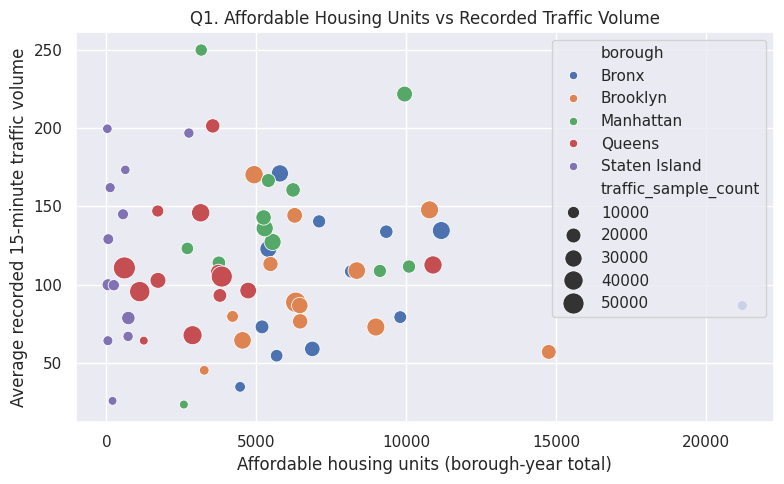

In [14]:
# Q1 — Scatter: affordable units vs average recorded traffic.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=plot_data, x="affordable_units", y="avg_traffic_volume",
                hue="borough", size="traffic_sample_count", sizes=(40, 250))
plt.title("Q1. Affordable Housing Units vs Recorded Traffic Volume")
plt.xlabel("Affordable housing units (borough-year total)")
plt.ylabel("Average recorded 15-minute traffic volume")
plt.tight_layout()
plt.show()

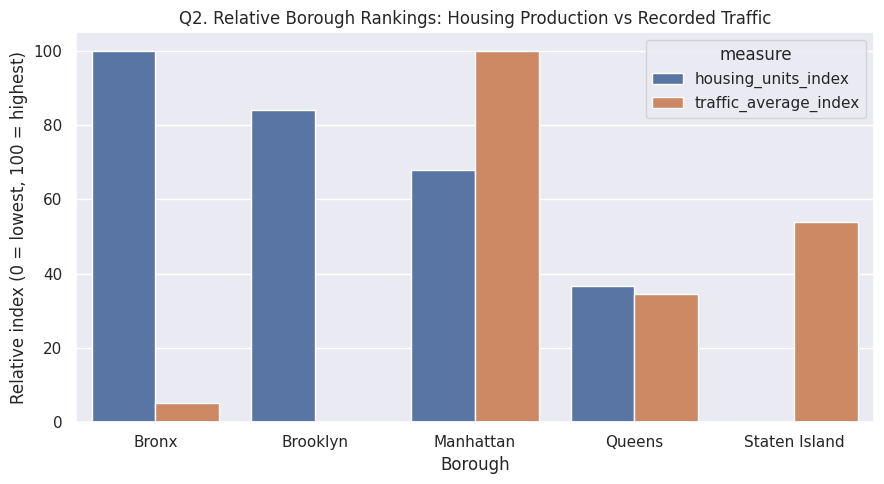

In [15]:
# Q2 — Compare both domains by borough using separate min-max indices.
# The index puts different units on a common 0–100 scale; it is NOT a raw-value comparison.
q2 = plot_data.groupby("borough", as_index=False).agg(
    housing_units=("affordable_units", "sum"),
    traffic_average=("avg_traffic_volume", "mean")
)
for col in ["housing_units", "traffic_average"]:
    span = q2[col].max() - q2[col].min()
    q2[col + "_index"] = 0 if span == 0 else (q2[col] - q2[col].min()) / span * 100

q2_long = q2.melt(
    id_vars="borough",
    value_vars=["housing_units_index", "traffic_average_index"],
    var_name="measure", value_name="index_0_to_100"
)
plt.figure(figsize=(9, 5))
sns.barplot(data=q2_long, x="borough", y="index_0_to_100", hue="measure")
plt.title("Q2. Relative Borough Rankings: Housing Production vs Recorded Traffic")
plt.xlabel("Borough")
plt.ylabel("Relative index (0 = lowest, 100 = highest)")
plt.tight_layout()
plt.show()

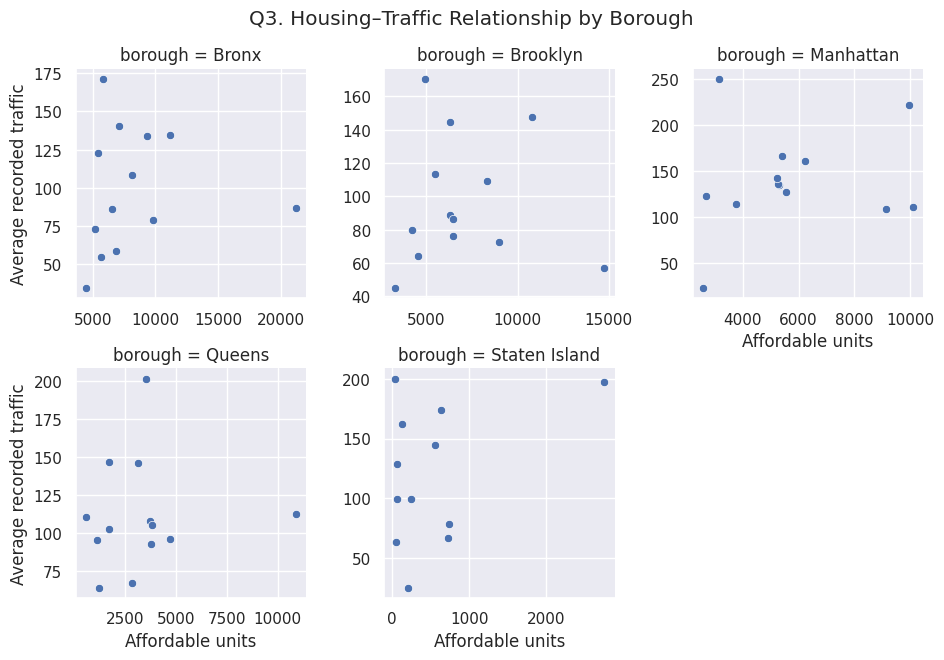

In [16]:
# Q3 — Faceted scatter by borough.
g = sns.FacetGrid(plot_data, col="borough", col_wrap=3, height=3.2, sharex=False, sharey=False)
g.map_dataframe(sns.scatterplot, x="affordable_units", y="avg_traffic_volume")
g.set_axis_labels("Affordable units", "Average recorded traffic")
g.fig.suptitle("Q3. Housing–Traffic Relationship by Borough", y=1.03)
plt.show()

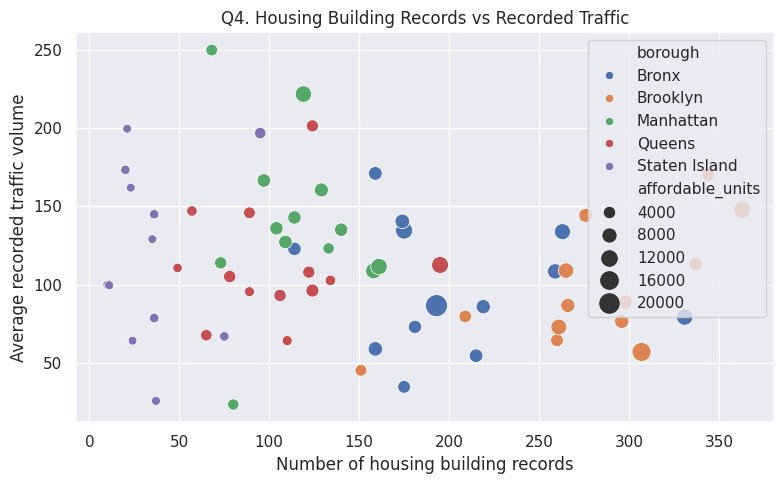

In [17]:
# Q4 — Building-record count vs traffic average.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=plot_data, x="housing_building_records", y="avg_traffic_volume",
                hue="borough", size="affordable_units", sizes=(40, 250))
plt.title("Q4. Housing Building Records vs Recorded Traffic")
plt.xlabel("Number of housing building records")
plt.ylabel("Average recorded traffic volume")
plt.tight_layout()
plt.show()

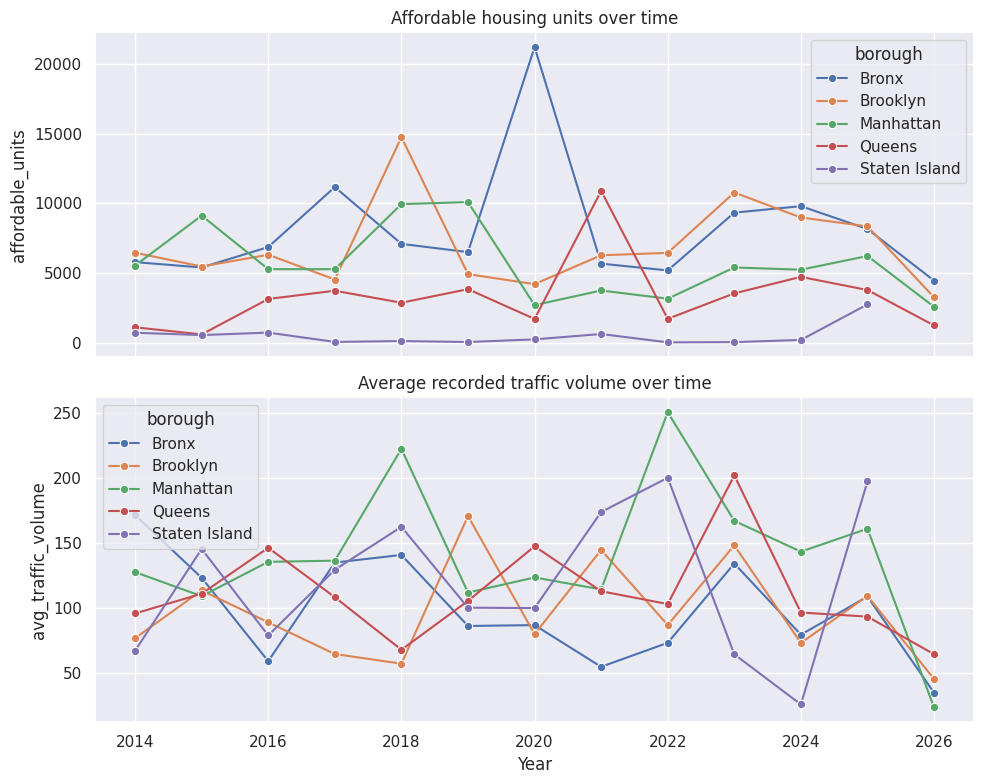

In [18]:
# Q5 — Two-panel trends, using only matched borough-year groups.
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
sns.lineplot(data=plot_data, x="year", y="affordable_units", hue="borough",
             marker="o", ax=axes[0])
axes[0].set_title("Affordable housing units over time")
sns.lineplot(data=plot_data, x="year", y="avg_traffic_volume", hue="borough",
             marker="o", ax=axes[1])
axes[1].set_title("Average recorded traffic volume over time")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

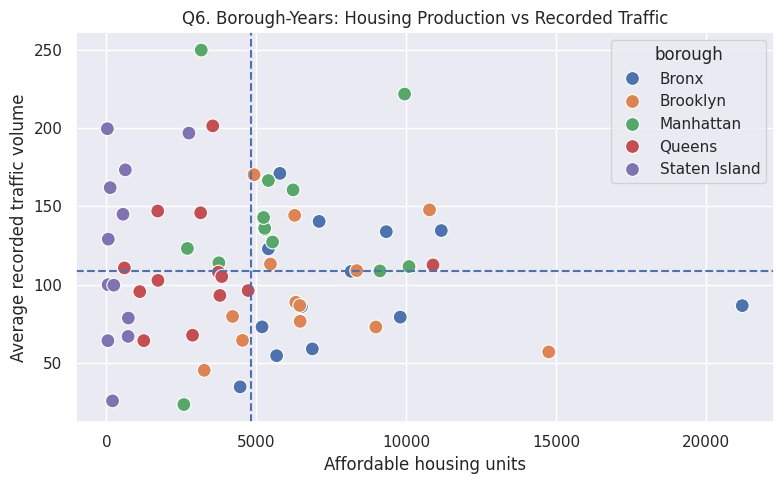

In [19]:
# Q6 — Quadrant scatter; median lines are descriptive reference points.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=plot_data, x="affordable_units", y="avg_traffic_volume",
                hue="borough", s=100)
plt.axvline(plot_data["affordable_units"].median(), linestyle="--")
plt.axhline(plot_data["avg_traffic_volume"].median(), linestyle="--")
plt.title("Q6. Borough-Years: Housing Production vs Recorded Traffic")
plt.xlabel("Affordable housing units")
plt.ylabel("Average recorded traffic volume")
plt.tight_layout()
plt.show()

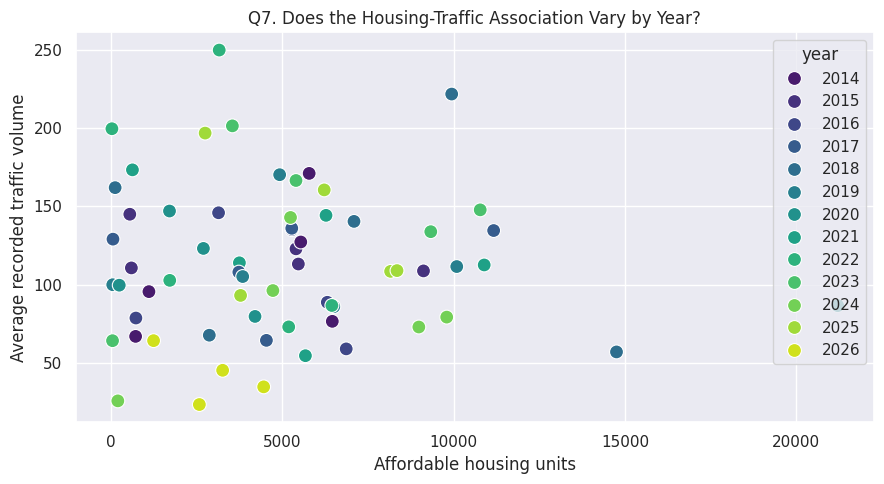

In [21]:
# Q7 - Color by year to inspect whether the relationship changes over time.

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=plot_data,
    x="affordable_units",
    y="avg_traffic_volume",
    hue=plot_data["year"].astype(int).astype(str),
    palette="viridis",
    s=100
)

plt.title("Q7. Does the Housing-Traffic Association Vary by Year?")
plt.xlabel("Affordable housing units")
plt.ylabel("Average recorded traffic volume")
plt.tight_layout()
plt.show()

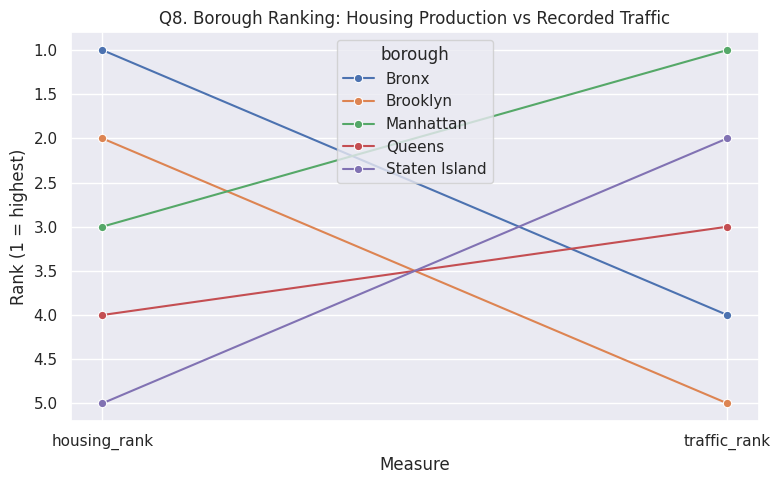

In [22]:
# Q8 — Compare borough rankings using matched years only.
rank_data = plot_data.groupby("borough", as_index=False).agg(
    housing_total=("affordable_units", "sum"),
    traffic_mean=("avg_traffic_volume", "mean")
)
rank_data["housing_rank"] = rank_data["housing_total"].rank(ascending=False, method="min")
rank_data["traffic_rank"] = rank_data["traffic_mean"].rank(ascending=False, method="min")
rank_long = rank_data.melt(id_vars="borough", value_vars=["housing_rank", "traffic_rank"],
                           var_name="measure", value_name="rank")
plt.figure(figsize=(8, 5))
sns.lineplot(data=rank_long, x="measure", y="rank", hue="borough", marker="o")
plt.gca().invert_yaxis()
plt.title("Q8. Borough Ranking: Housing Production vs Recorded Traffic")
plt.xlabel("Measure")
plt.ylabel("Rank (1 = highest)")
plt.tight_layout()
plt.show()

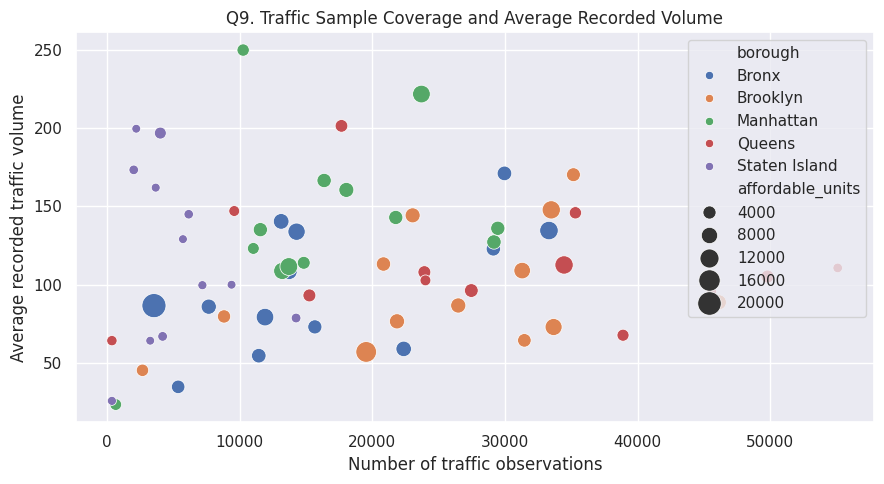

In [23]:
# Q9 — Bubble chart: bubble size shows the number of traffic observations.
plt.figure(figsize=(9, 5))
sns.scatterplot(data=plot_data, x="traffic_sample_count", y="avg_traffic_volume",
                hue="borough", size="affordable_units", sizes=(40, 300))
plt.title("Q9. Traffic Sample Coverage and Average Recorded Volume")
plt.xlabel("Number of traffic observations")
plt.ylabel("Average recorded traffic volume")
plt.tight_layout()
plt.show()

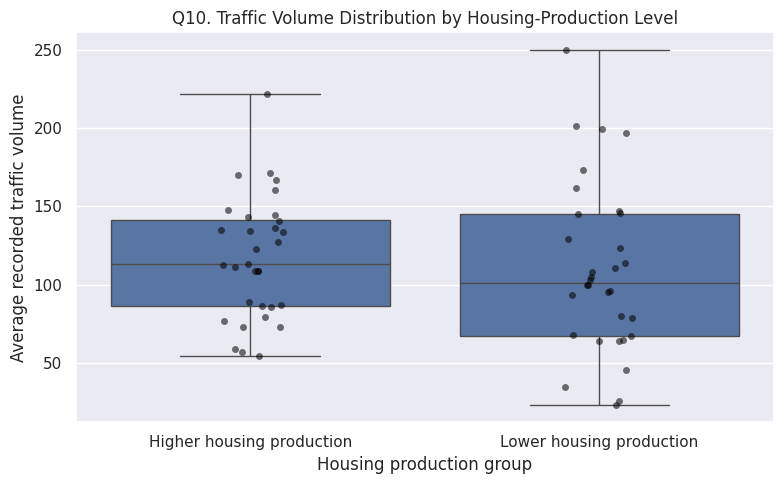

In [24]:
# Q10 — Split borough-years into lower/higher housing production using the median.
median_units = plot_data["affordable_units"].median()
plot_data["housing_level"] = np.where(
    plot_data["affordable_units"] >= median_units, "Higher housing production", "Lower housing production"
)
plt.figure(figsize=(8, 5))
sns.boxplot(data=plot_data, x="housing_level", y="avg_traffic_volume")
sns.stripplot(data=plot_data, x="housing_level", y="avg_traffic_volume",
              color="black", alpha=0.55)
plt.title("Q10. Traffic Volume Distribution by Housing-Production Level")
plt.xlabel("Housing production group")
plt.ylabel("Average recorded traffic volume")
plt.tight_layout()
plt.show()

In [25]:

# Find the borough-year with the highest affordable housing units
max_housing = plot_data.loc[plot_data["affordable_units"].idxmax()]

# Find the borough-year with the highest average traffic volume
max_traffic = plot_data.loc[plot_data["avg_traffic_volume"].idxmax()]

print("Highest affordable housing production:")
print(max_housing[["borough", "year", "affordable_units"]])

print("\nHighest average recorded traffic:")
print(max_traffic[["borough", "year", "avg_traffic_volume"]])

# Calculate the correlation
correlation = plot_data["affordable_units"].corr(
    plot_data["avg_traffic_volume"]
)

print("\nCorrelation:", correlation)


Highest affordable housing production:
borough               Bronx
year                   2020
affordable_units    21206.0
Name: 13, dtype: object

Highest average recorded traffic:
borough                Manhattan
year                        2022
avg_traffic_volume    250.220892
Name: 57, dtype: object

Correlation: -0.032302178062661606


## 9. Interpretation, limitations, and city impact

Complete this section after running the notebook. Use actual numbers and chart observations.

### Findings (fill in from your results)
### Findings

- The borough/year with the largest affordable-unit total in the matched sample was **Bronx, 2020, with 21,206 affordable housing units**.
- The borough/year with the highest average recorded traffic volume was **Manhattan, 2022, with an average of 250.22**.
- The scatter plot suggests **no clear pattern**, supported by a correlation coefficient of approximately **-0.0323**, indicating an extremely weak negative relationship.
- Important exceptions or surprising patterns: **The Bronx recorded the highest affordable housing production, while Manhattan recorded the highest average traffic volume. This suggests that higher affordable housing production does not necessarily correspond to higher recorded traffic volume.**
### Limitations
1. Traffic volume counts are samples at selected locations and times; they do not represent continuous, complete borough-wide traffic.
2. The number of traffic observations differs by location and year, so averages may have unequal coverage.
3. Housing project start date reflects the project financing/regulatory milestone described by HPD, not necessarily occupancy or completion.
4. Borough-level aggregation hides neighborhood-level differences.
5. Other factors (population, employment, road design, transit availability, events, weather) may affect traffic.
6. Correlation does not establish causation.

### Potential impact
The analysis may help city planners identify borough-years where affordable-housing activity and recorded roadway demand occur together, prompting more detailed neighborhood-level transport and infrastructure studies.

## 10. Contribution tracking (team of five)

Replace Member 1–5 with actual names. Record real contributions only.

| Team member | Research questions | Visualizations | Other contribution |
|---|---|---|---|
| Member 1 | Q1–Q2 | Q1–Q2 | Housing EDA and data dictionary |
| Member 2 | Q3–Q4 | Q3–Q4 | Housing cleaning and validation |
| Member 3 | Q5–Q6 | Q5–Q6 | Traffic EDA and aggregation |
| Member 4 | Q7–Q8 | Q7–Q8 | Integration and post-join cleaning |
| Member 5 | Q9–Q10 | Q9–Q10 | Website, testing, README and deployment |

All members should review the full analysis and understand the final story. Adjust this table to reflect the work actually performed.

## 11. Sources
- Housing: https://data.cityofnewyork.us/Housing-Development/Housing-New-York-Units-by-Building/hg8x-zxpr
- Transportation: https://data.cityofnewyork.us/Transportation/Automated-Traffic-Volume-Counts/7ym2-wayt
- Housing documentation: https://www.nyc.gov/site/hpd/about/open-data.page

## Final submission reminder
Save the executed notebook with outputs, the integrated CSV, the website source code, and a README in the team's GitHub repository. Confirm that the deployed website works before submission.